In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("./btcusd_1-min_data.csv")
df.head(5)

,Timestamp,Open,High,Low,Close,Volume
0,1325376060,4.58,4.58,4.58,4.58,0.0
1,1325376120,4.58,4.58,4.58,4.58,0.0
2,1325376180,4.58,4.58,4.58,4.58,0.0
3,1325376240,4.58,4.58,4.58,4.58,0.0
4,1325376300,4.58,4.58,4.58,4.58,0.0


In [3]:
df["Datetime"] = pd.to_datetime(df["Timestamp"], unit="s")
df.set_index("Datetime", inplace=True)
df.drop(columns=['Timestamp'], inplace=True)
df = df.resample('D').first()
test_range = df['2018-01-01':'2026-01-01']
with open("btcusd_testrange.csv", "w") as f:
    test_range.to_csv(f)

In [4]:
test_range.head(5)

,Open,High,Low,Close,Volume
Datetime,,,,,
2018-01-01,13880.00,13906.37,13841.00,13841.01,4.967997
2018-01-02,13394.20,13493.88,13394.20,13493.88,4.206154
2018-01-03,14670.96,14679.00,14647.50,14654.99,21.737184
2018-01-04,15155.62,15155.62,15107.70,15153.00,9.247436
2018-01-05,15143.67,15199.98,15135.19,15150.00,30.085994


In [5]:
type(test_range['Close'] - test_range['Close'].shift(1))

pandas.core.series.Series

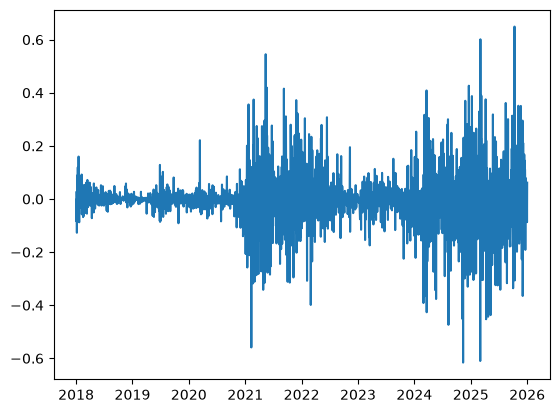

In [7]:
# Buy-and-hold
daily_pnl = test_range['Close'].shift(1) - test_range['Close']
returns = daily_pnl / test_range['Close'].iloc[0]
plt.plot(returns.index, returns)

In [8]:
import math
# Sharpie ratio of buy-and-hold
# Risk-free rate of 4%/year
excess_returns = returns - 0.04/365
sharpie_ratio = math.sqrt(365) * excess_returns.mean() / excess_returns.std()

In [9]:
sharpie_ratio

np.float64(-0.39061981805014234)

In [12]:
def calculate_max_drawdown(returns):
    # Assuming that returns does have a freaking index
    # And, also, it is really returns. Else it doesn't
    # work.
    wealth = (1 + returns).cumprod()
    running_max = wealth.cummax()
    drawdown = wealth / running_max - 1  # <= 0

    max_drawdown = drawdown.min() if len(drawdown) else 0.0

    max_duration = 0
    current_duration = 0
    for dd in drawdown:
        if dd < 0:
            current_duration += 1
            max_duration = max(max_duration, current_duration)
        else:
            current_duration = 0

    return max_drawdown, max_duration

In [13]:
calculate_max_drawdown(returns)

(np.float64(-0.9999999995031303), 2573)